# 🏦 Analisis & Segmentasi Nasabah Bank — Deposito Berjangka

**Tugas Data Mining — Eksplorasi Data** ([soal](soal.pdf))

Dataset: **Bank Marketing (UCI)** — 45.211 nasabah, 17 variabel, hasil kampanye pemasaran telepon sebuah bank untuk menawarkan **deposito berjangka** (`Deposit`: yes/no).

| Soal | Pertanyaan | Metode |
|---|---|---|
| 1 | Seleksi ≥ 5 variabel paling relevan | Random Forest feature importance |
| 2 | Profil nasabah saat ini | Statistik deskriptif & visualisasi |
| 3 | Perbedaan profil nasabah yang berdeposito vs tidak | Uji Mann-Whitney U & Chi-Square |
| 4 | Segmentasi seluruh nasabah | K-Means (Elbow & Silhouette) |
| 5 | Penyebab nasabah tidak berdeposito berdasarkan segmen | Analisis profil per segmen |

## Load Data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.stats import chi2_contingency, mannwhitneyu
import warnings

warnings.filterwarnings("ignore")

df = pd.read_excel("data/bank_marketing.xlsx", sheet_name=0)
df["Deposit_bin"] = (df["Deposit"] == "yes").astype(int)

print(df.shape)
print(df.dtypes)
print(df["Deposit"].value_counts(normalize=True))

(45211, 18)
age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day            int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
Deposit          str
Deposit_bin    int64
dtype: object
Deposit
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


## Soal 1 — Seleksi Variabel

Random Forest dilatih pada seluruh variabel, lalu dipilih **7 variabel** dengan *feature importance* tertinggi.

     Variabel  Importance
3    duration    0.291025
1     balance    0.110048
0         age    0.102857
2         day    0.089499
14      month    0.086006
15   poutcome    0.052936
5       pdays    0.051337
7         job    0.049189
4    campaign    0.038429
9   education    0.027579
11    housing    0.026343
6    previous    0.021580
8     marital    0.021528
13    contact    0.019871
12       loan    0.009931
10    default    0.001843


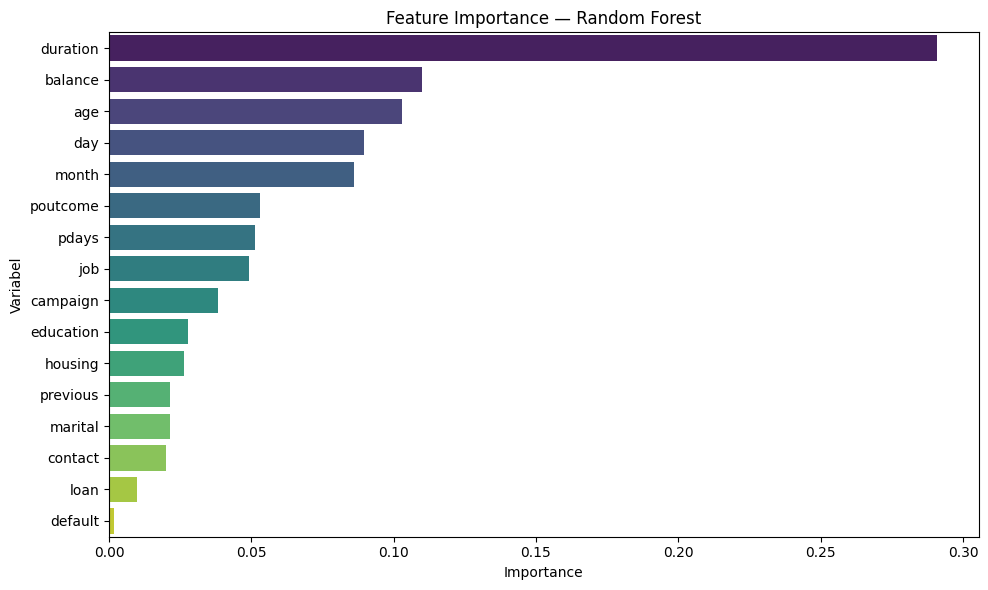


Variabel terpilih: ['duration', 'balance', 'age', 'day', 'month', 'poutcome', 'pdays']


In [4]:
cat_cols = df.select_dtypes(include="object").columns.drop("Deposit")
num_cols = df.select_dtypes(include=np.number).columns.drop("Deposit_bin")

df_enc = df.copy()
le = LabelEncoder()
for col in cat_cols:
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))

feature_cols = list(num_cols) + list(cat_cols)
X = df_enc[feature_cols]
y = df_enc["Deposit_bin"]

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X, y)

importance_df = pd.DataFrame(
    {"Variabel": feature_cols, "Importance": rf.feature_importances_}
).sort_values("Importance", ascending=False)

print(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Variabel",
    palette="viridis",
)
plt.title("Feature Importance — Random Forest")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150)
plt.show()

top_vars = importance_df.head(7)["Variabel"].tolist()
print("\nVariabel terpilih:", top_vars)

## Soal 2 — Profil Nasabah Bank X

=== PROFIL NASABAH BANK X ===

            count     mean      std     min    25%    50%     75%       max
age       45211.0    40.94    10.62    18.0   33.0   39.0    48.0      95.0
balance   45211.0  1362.27  3044.77 -8019.0   72.0  448.0  1428.0  102127.0
day       45211.0    15.81     8.32     1.0    8.0   16.0    21.0      31.0
duration  45211.0   258.16   257.53     0.0  103.0  180.0   319.0    4918.0
campaign  45211.0     2.76     3.10     1.0    1.0    2.0     3.0      63.0
pdays     45211.0    40.20   100.13    -1.0   -1.0   -1.0    -1.0     871.0
previous  45211.0     0.58     2.30     0.0    0.0    0.0     0.0     275.0

JOB:
job
blue-collar      21.5
management       20.9
technician       16.8
admin.           11.4
services          9.2
retired           5.0
self-employed     3.5
entrepreneur      3.3
unemployed        2.9
housemaid         2.7
student           2.1
unknown           0.6

MARITAL:
marital
married     60.2
single      28.3
divorced    11.5

EDUCATION:
educat

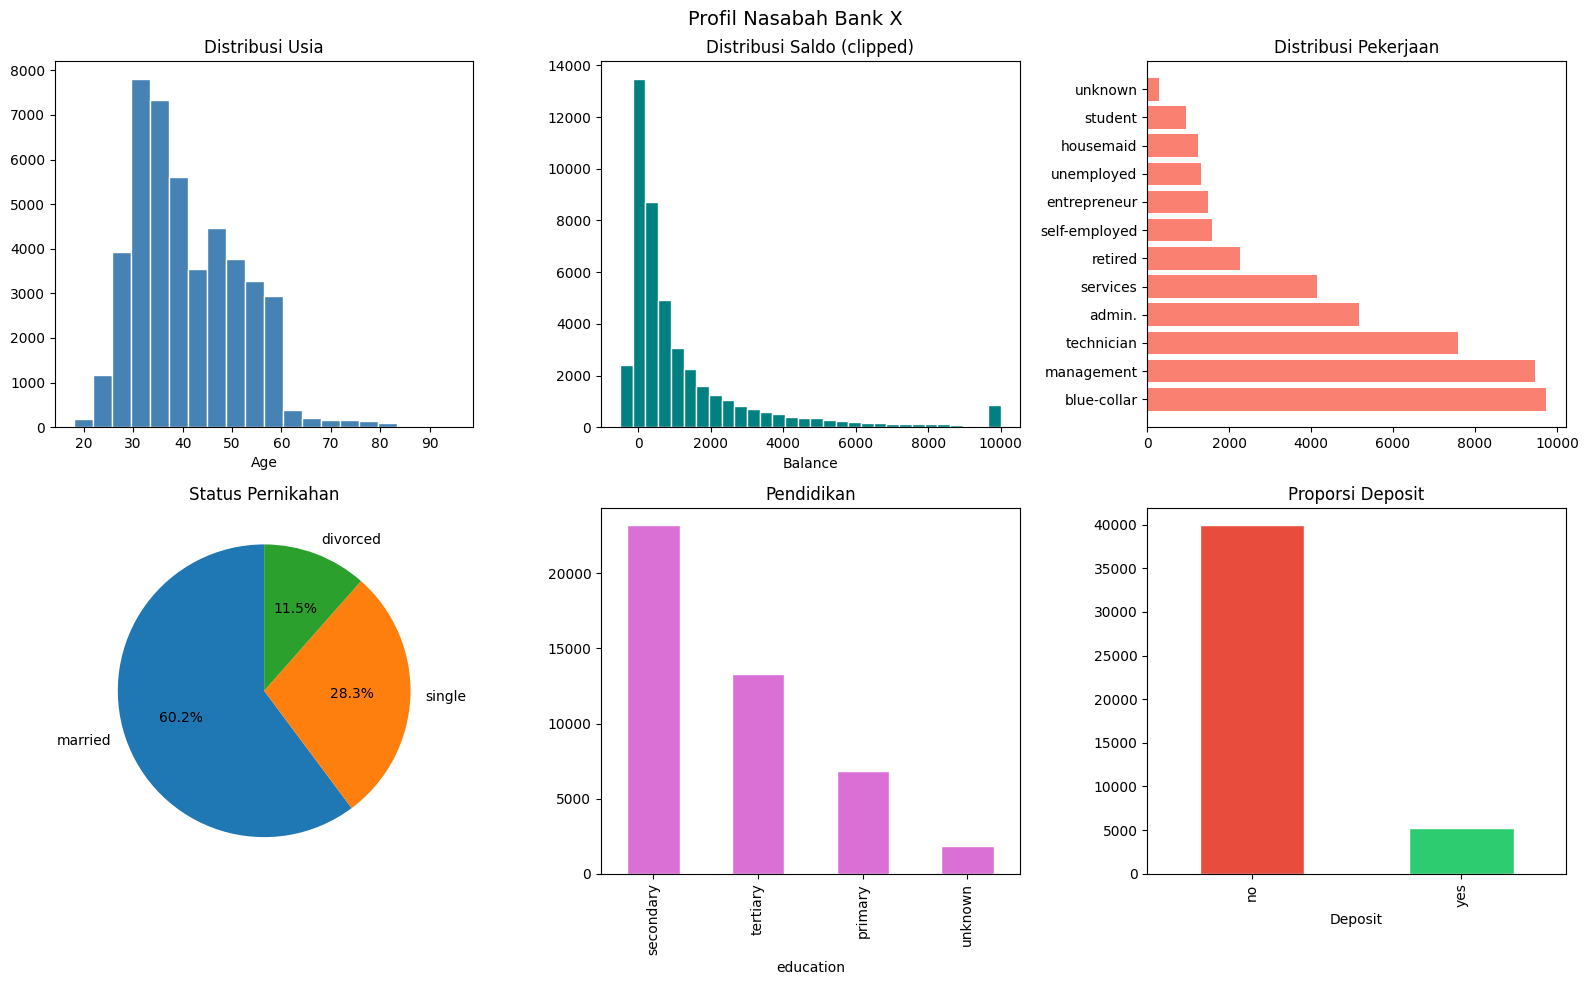

In [5]:
# ── Statistik deskriptif numerik ──────────────────────────────
print("=== PROFIL NASABAH BANK X ===\n")
print(df[num_cols].describe().T.round(2))

# ── Distribusi kategorik ──────────────────────────────────────
for col in cat_cols:
    print(f"\n{col.upper()}:")
    print(df[col].value_counts(normalize=True).mul(100).round(1).to_string())

# ── Visualisasi ───────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Profil Nasabah Bank X", fontsize=14)

# Age distribution
axes[0, 0].hist(df["age"], bins=20, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Distribusi Usia")
axes[0, 0].set_xlabel("Age")

# Balance distribution
axes[0, 1].hist(
    df["balance"].clip(-500, 10000), bins=30, color="teal", edgecolor="white"
)
axes[0, 1].set_title("Distribusi Saldo (clipped)")
axes[0, 1].set_xlabel("Balance")

# Job
job_counts = df["job"].value_counts()
axes[0, 2].barh(job_counts.index, job_counts.values, color="salmon")
axes[0, 2].set_title("Distribusi Pekerjaan")

# Marital
df["marital"].value_counts().plot.pie(
    ax=axes[1, 0], autopct="%1.1f%%", startangle=90
)
axes[1, 0].set_title("Status Pernikahan")
axes[1, 0].set_ylabel("")

# Education
df["education"].value_counts().plot.bar(
    ax=axes[1, 1], color="orchid", edgecolor="white"
)
axes[1, 1].set_title("Pendidikan")

# Deposit ratio
df["Deposit"].value_counts().plot.bar(
    ax=axes[1, 2], color=["#e74c3c", "#2ecc71"], edgecolor="white"
)
axes[1, 2].set_title("Proporsi Deposit")

plt.tight_layout()
plt.savefig("images/profil_nasabah.png", dpi=150)
plt.show()

## Soal 3 — Perbedaan Profil: Deposito vs Tidak

- Variabel numerik: **uji Mann-Whitney U** (non-parametrik, karena distribusi tidak normal)
- Variabel kategorik: **uji Chi-Square**

Tanda `*` menunjukkan perbedaan signifikan (p < 0,05).

=== PERBANDINGAN PROFIL DEPOSIT vs TIDAK ===

Uji Mann-Whitney U (numerik):
Variabel           Mean_No   Mean_Yes    p-value
--------------------------------------------------
age                  40.84      41.67     0.0628
balance            1303.71    1804.27     0.0000 *
day                  15.89      15.16     0.0000 *
duration            221.18     537.29     0.0000 *
campaign              2.85       2.14     0.0000 *
pdays                36.42      68.70     0.0000 *
previous              0.50       1.17     0.0000 *

Uji Chi-Square (kategorik):
Variabel              Chi2    p-value
-----------------------------------
job                 836.11     0.0000 *
marital             196.50     0.0000 *
education           238.92     0.0000 *
default              22.20     0.0000 *
housing             874.82     0.0000 *
loan                209.62     0.0000 *
contact            1035.71     0.0000 *
month              3061.84     0.0000 *
poutcome           4391.51     0.0000 *


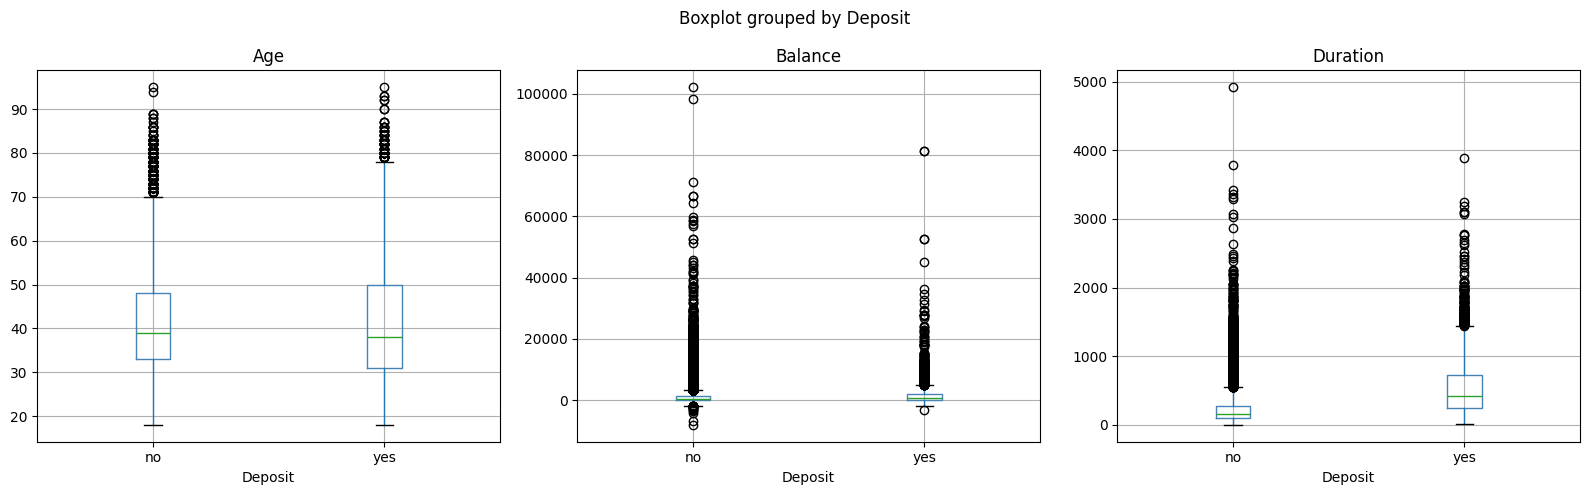

In [ ]:
print(" PERBANDINGAN PROFIL DEPOSIT vs TIDAK \n")

print("Uji Mann-Whitney U (numerik):")
print(f"{'Variabel':<15} {'Mean_No':>10} {'Mean_Yes':>10} {'p-value':>10}")
print("-" * 50)

for col in num_cols:
    grp_no = df[df["Deposit"] == "no"][col].dropna()
    grp_yes = df[df["Deposit"] == "yes"][col].dropna()
    _, p = mannwhitneyu(grp_no, grp_yes, alternative="two-sided")
    print(
        f"{col:<15} {grp_no.mean():>10.2f} {grp_yes.mean():>10.2f} {p:>10.4f}"
        + (" *" if p < 0.05 else "")
    )

print("\nUji Chi-Square (kategorik):")
print(f"{'Variabel':<15} {'Chi2':>10} {'p-value':>10}")
print("-" * 35)

for col in cat_cols:
    ct = pd.crosstab(df[col], df["Deposit"])
    chi2, p, _, _ = chi2_contingency(ct)
    print(f"{col:<15} {chi2:>10.2f} {p:>10.4f}" + (" *" if p < 0.05 else ""))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Karakteristik Berdasarkan Keputusan Deposit", fontsize=13)

key_num = ["age", "balance", "duration"]
for i, col in enumerate(key_num):
    df.boxplot(column=col, by="Deposit", ax=axes[i], 
               boxprops=dict(color="steelblue"))
    axes[i].set_title(col.capitalize())
    axes[i].set_xlabel("Deposit")

plt.tight_layout()
plt.savefig("images/perbandingan_deposit.png", dpi=150)
plt.show()

## Soal 4 — Segmentasi Nasabah (K-Means)

Variabel terpilih dari Soal 1 distandardisasi, lalu jumlah cluster ditentukan dengan Elbow Method dan Silhouette Score.

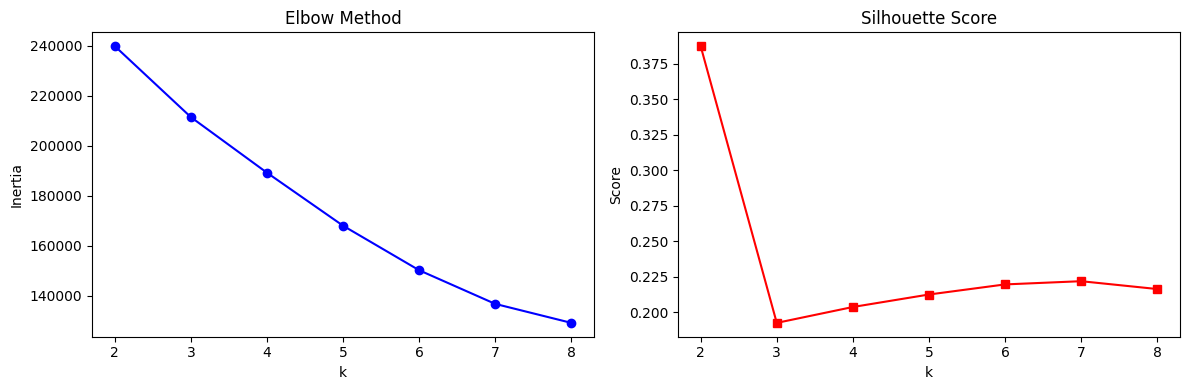

Optimal k: 2

=== PROFIL TIAP SEGMEN ===

             n  age_mean  balance_mean  duration_mean  campaign_mean  \
Segment                                                                
0        37824     40.97       1328.43         258.23           2.90   
1         7387     40.79       1535.56         257.84           2.08   

         deposit_rate  deposit_rate_pct  
Segment                                  
0                0.10              10.0  
1                0.19              19.0  

Segmen 0 (n=37824):
  Top Job     : blue-collar
  Top Marital : married
  Top Education: secondary
  Deposit Rate: 10.2%

Segmen 1 (n=7387):
  Top Job     : management
  Top Marital : married
  Top Education: secondary
  Deposit Rate: 19.3%


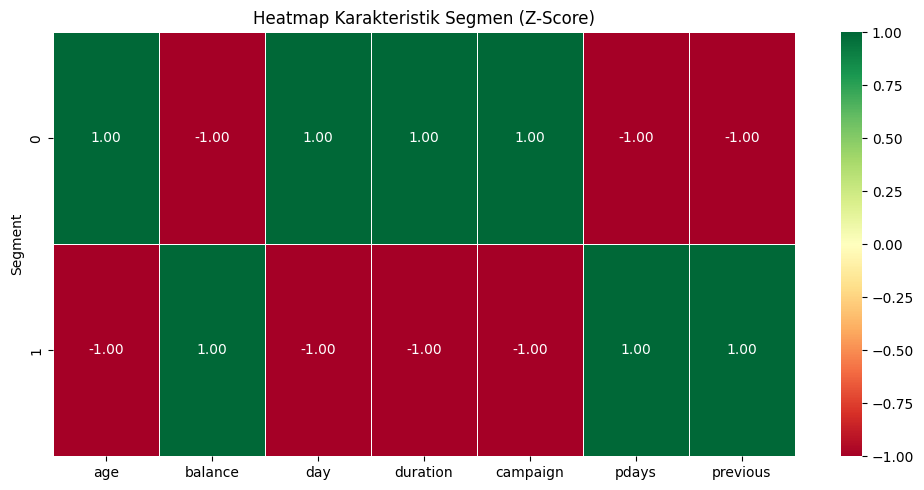

In [ ]:
cluster_vars = top_vars  # variabel terpilih dari soal 1
X_cluster = df_enc[cluster_vars].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

inertia, sil_scores = [], []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertia, "bo-")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, sil_scores, "rs-")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.savefig("images/elbow_silhouette.png", dpi=150)
plt.show()

optimal_k = k_range[np.argmax(sil_scores)]
print(f"Optimal k: {optimal_k}")

km_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Segment"] = km_final.fit_predict(X_scaled)

print("\n PROFIL TIAP SEGMEN \n")
segment_profile = df.groupby("Segment").agg(
    n=("age", "count"),
    age_mean=("age", "mean"),
    balance_mean=("balance", "mean"),
    duration_mean=("duration", "mean"),
    campaign_mean=("campaign", "mean"),
    deposit_rate=("Deposit_bin", "mean"),
).round(2)
segment_profile["deposit_rate_pct"] = (
    segment_profile["deposit_rate"] * 100
).round(1)
print(segment_profile)

for seg in sorted(df["Segment"].unique()):
    sub = df[df["Segment"] == seg]
    print(f"\nSegmen {seg} (n={len(sub)}):")
    print(f"  Top Job     : {sub['job'].mode()[0]}")
    print(f"  Top Marital : {sub['marital'].mode()[0]}")
    print(f"  Top Education: {sub['education'].mode()[0]}")
    print(f"  Deposit Rate: {sub['Deposit_bin'].mean()*100:.1f}%")

plt.figure(figsize=(10, 5))
seg_num = df.groupby("Segment")[list(num_cols)].mean()
seg_scaled = pd.DataFrame(
    StandardScaler().fit_transform(seg_num),
    index=seg_num.index,
    columns=seg_num.columns,
)
sns.heatmap(seg_scaled, annot=True, fmt=".2f", cmap="RdYlGn", linewidths=0.5)
plt.title("Heatmap Karakteristik Segmen (Z-Score)")
plt.tight_layout()
plt.savefig("images/segment_heatmap.png", dpi=150)
plt.show()

## Soal 5 — Penyebab Nasabah Tidak Berinvestasi per Segmen

ANALISIS PENYEBAB TIDAK BERINVESTASI PER SEGMEN 

--- Segmen 0 | Deposit Rate: 10.2% ---
  Avg Balance  :     1328
  Avg Duration :      258 detik
  Avg Campaign :      2.9 kali
  poutcome     : unknown
  housing loan : yes
  personal loan: no

--- Segmen 1 | Deposit Rate: 19.3% ---
  Avg Balance  :     1536
  Avg Duration :      258 detik
  Avg Campaign :      2.1 kali
  poutcome     : failure
  housing loan : yes
  personal loan: no

Distribusi Deposit per Segmen (%):
Deposit    no   yes
Segment            
0        89.8  10.2
1        80.7  19.3


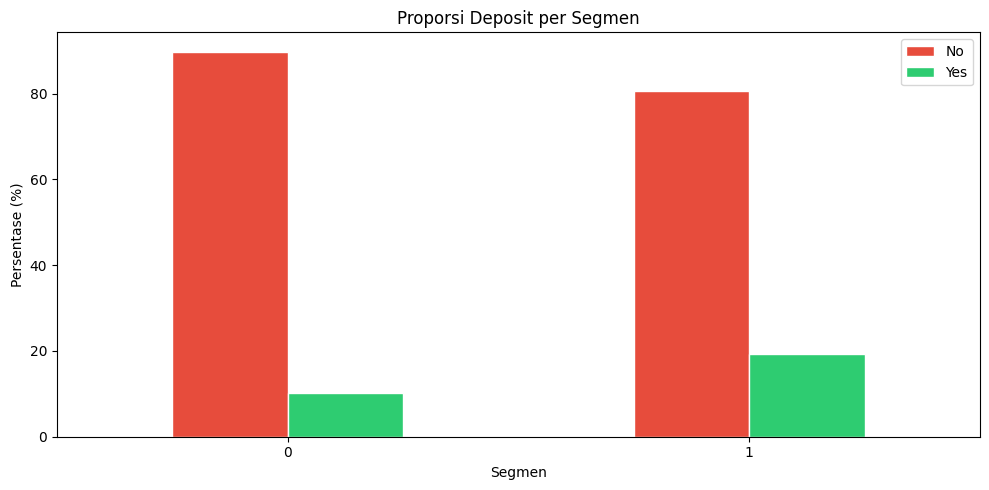

In [8]:
print("ANALISIS PENYEBAB TIDAK BERINVESTASI PER SEGMEN \n")

for seg in sorted(df["Segment"].unique()):
    sub = df[df["Segment"] == seg]
    no_dep = sub[sub["Deposit"] == "no"]
    rate = sub["Deposit_bin"].mean()

    print(f"--- Segmen {seg} | Deposit Rate: {rate*100:.1f}% ---")
    print(f"  Avg Balance  : {sub['balance'].mean():>8.0f}")
    print(f"  Avg Duration : {sub['duration'].mean():>8.0f} detik")
    print(f"  Avg Campaign : {sub['campaign'].mean():>8.1f} kali")
    print(f"  poutcome     : {sub['poutcome'].mode()[0]}")
    print(f"  housing loan : {sub['housing'].mode()[0]}")
    print(f"  personal loan: {sub['loan'].mode()[0]}")
    print()

ct = pd.crosstab(df["Segment"], df["Deposit"], normalize="index").mul(100).round(1)
print("Distribusi Deposit per Segmen (%):")
print(ct)

ct.plot(kind="bar", figsize=(10, 5), color=["#e74c3c", "#2ecc71"], edgecolor="white")
plt.title("Proporsi Deposit per Segmen")
plt.xlabel("Segmen")
plt.ylabel("Persentase (%)")
plt.legend(["No", "Yes"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/deposit_per_segmen.png", dpi=150)
plt.show()